In [21]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.ticker import FuncFormatter
from io import StringIO
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

from scipy.stats import linregress

In [22]:
mpl.rcParams['figure.dpi'] = 500

In [23]:
# Observational data

#ATCA_data = np.loadtxt('../data_radio_apep.dat')
#nu_ATCA, nu_ATCA_err = ATCA_data[:,0], ATCA_data[:,2]
#flux_ATCA, flux_ATCA_err = ATCA_data[:,1], ATCA_data[:,3] 

# MSX (Benaglia+2010)
msx_data = np.loadtxt('Benaglia_2010.dat')
nu_msx, nu_msx_err = msx_data[:,0], msx_data[:,1]
flux_msx, flux_msx_err = msx_data[:,2], msx_data[:,2]*0.1

# jVLA (Benaglia+2021)
jvla_data = np.loadtxt('Benaglia_2021.dat')
nu_jvla, nu_jvla_err = jvla_data[:,0], jvla_data[:,2]
flux_jvla, flux_jvla_err = 1000.*jvla_data[:,1],1000.*jvla_data[:,3]

# jVLA (Benaglia+2021)
jvla_B_data = np.loadtxt('Benaglia_2021_B.dat')
nu_jvla_B, nu_jvla_B_err = jvla_B_data[:,0], jvla_B_data[:,2]
flux_jvla_B, flux_jvla_B_err = 1000.*jvla_B_data[:,1],1000.*jvla_B_data[:,3]

# Feathered data (Moutzouri+2022)
feat_data = np.loadtxt('Moutzouri_2022.dat')
nu_feat, nu_feat_err = feat_data[:,0], feat_data[:,1]/2.
flux_feat, flux_feat_err = (feat_data[:,2]-feat_data[:,3]), 0.05*(feat_data[:,2]-feat_data[:,3])

# VdE 2022
nu_VdE = np.array([0.8875])
nu_VdE_err = np.array([0.288/2.])

HD_319881 = np.array([5.97])
HD_319881_err = 0.05*HD_319881

RCW_49_S1 = np.array([12.6])
RCW_49_S1_err = 0.05*RCW_49_S1

G1 = np.array([8.0])
G1_err = 0.05*G1

HIP_98418 = np.array([5.3])
HIP_98418_err = 0.05*HIP_98418

HIP_88652 = np.array([2.24])
HIP_88652_err = 0.05*HIP_88652

# VdE 2022 (Vela X-1)
nu_VX1 = np.array([1.3])
nu_VX1_err = np.array([0.856/2])

V_X1 = np.array([5.27])
V_X1_err = np.array([0.07])

In [24]:
systems = ["BD+43", "G1", "G3", "Vela_X-1"]
#systems = ["BD+43"]

In [25]:
data = {}

for sys in systems:
    data[sys] = {}
    
    files = {
        "syn_unabs": f"../../../output/S_syn_{sys}_RS.dat",
        "syn": f"../../../output/S_syn_abs_{sys}_BOTH.dat",
        "ff_HL": f"../../../output/S_ff_{sys}_FS.dat",
        "ff_IL": f"../../../output/S_ionized_{sys}_FS.dat",
    }

    for key, archivo in files.items():

        if not os.path.exists(archivo):
            print(f"Missing file: {archivo}")
            continue

        try:
            archivo_data = read_file(archivo)

            if len(archivo_data) == 0:
                print(f"Empty file: {archivo}")
                continue

            data[sys][f"nu_{key}"] = archivo_data[:, 0].copy()/1e9
            data[sys][key]       = archivo_data[:, 1].copy()

        except Exception as e:
            print(f"Reading error {archivo}: {e}")
            

In [26]:
total = {}

for sys in systems:

    components = [
        ("nu_syn", "syn"),
        ("nu_ff_HL", "ff_HL"),
        ("nu_ff_IL", "ff_IL"),
    ]

    nu_min = min(
        data[sys][nu_key].min()
        for nu_key, _ in components
    )

    nu_max = max(
        data[sys][nu_key].max()
        for nu_key, _ in components
    )

    nu_tot = np.geomspace(nu_min, nu_max, 400)

    S_tot = np.zeros_like(nu_tot)

    for nu_key, S_key in components:
        S_tot += np.interp(
            nu_tot,
            data[sys][nu_key],
            data[sys][S_key],
            left=0,
            right=0
        )

    total[sys] = {
        "nu_tot": nu_tot,
        "S_tot": S_tot
    }

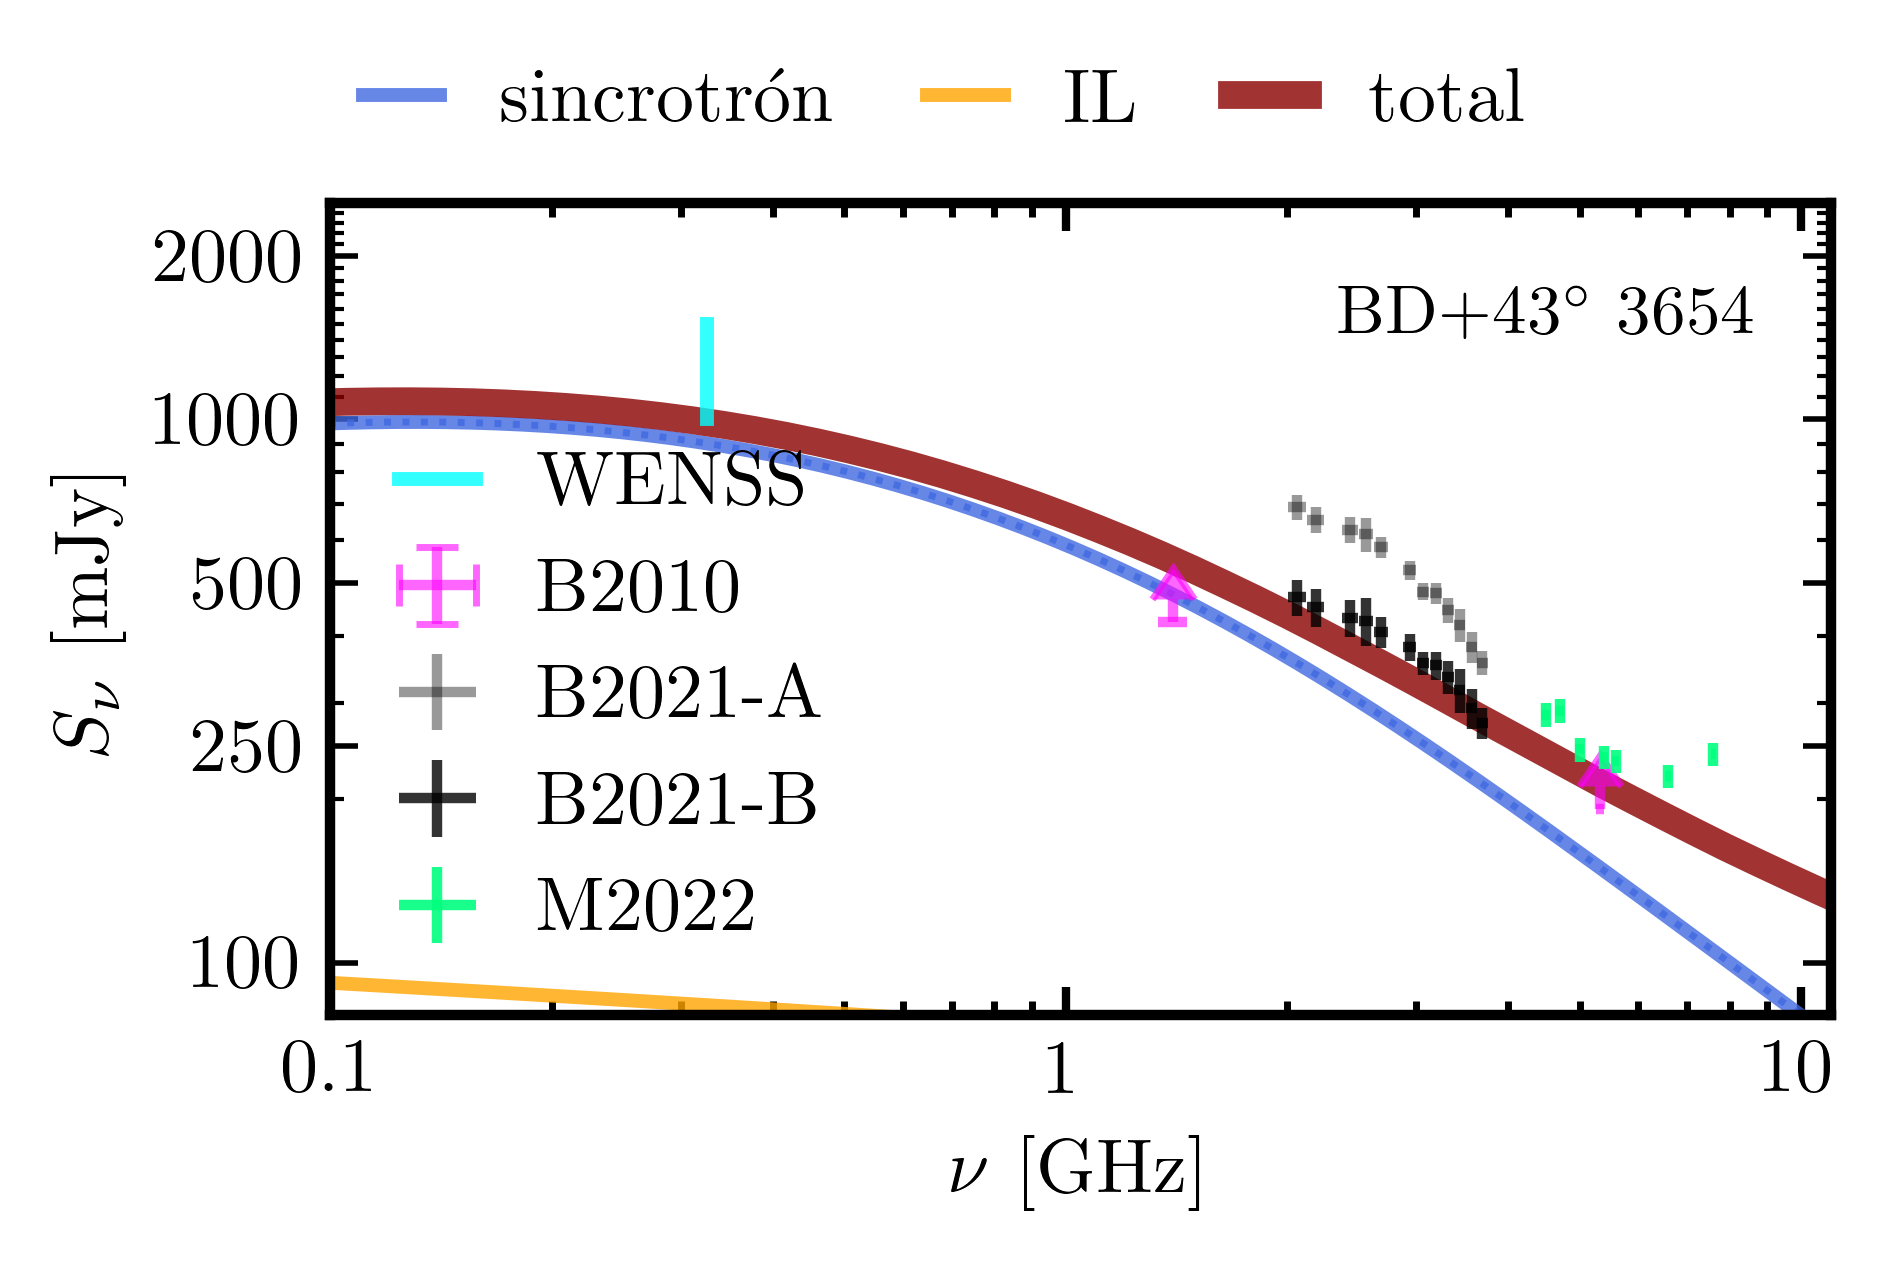

In [27]:
fig, ax = plt.subplots(
    figsize=(0.6*text_width, 2./3.*0.6*text_width),
    constrained_layout=True,
)
ax.set_xscale('log')
ax.set_yscale('log')
ax.plot(
    data['BD+43']["nu_syn"],
    data['BD+43']["syn"],
    color="royalblue", lw=2, alpha=0.8,
    label=r"sincrotrón"
)
ax.plot(
    data['BD+43']["nu_syn_unabs"],
    data['BD+43']["syn_unabs"],
    color="royalblue", lw=1, ls=':', alpha=0.8,
    label=r""
)
ax.plot(
    data['BD+43']["nu_ff_IL"],
    data['BD+43']["ff_IL"],
    color="orange", lw=2, alpha=0.8,
    label=r"IL"
)
ax.plot(
    total['BD+43']["nu_tot"],
    total['BD+43']["S_tot"],
    color="darkred", lw=4, alpha=0.8,
    label='total'
)
ax.annotate(r"BD+43$^\circ$ 3654",
                xy=(0.95,0.9),
                xycoords="axes fraction",
                ha="right",
                va="top"
                )
ax.errorbar(nu_msx, flux_msx, yerr=flux_msx_err, xerr=nu_msx_err,
            lolims=True, ecolor='magenta', alpha=0.6, fmt='none',
            label='B2010', zorder=2)
ax.errorbar(nu_jvla, flux_jvla, yerr=flux_jvla_err, xerr=nu_jvla_err,
            ecolor='k', alpha=0.4, fmt='none', label='B2021-A', zorder=2)
ax.errorbar(nu_jvla_B, flux_jvla_B, yerr=flux_jvla_B_err, xerr=nu_jvla_B_err,
            ecolor='k', alpha=0.8, fmt='none', label='B2021-B', zorder=2)
ax.errorbar(nu_feat, flux_feat, yerr=flux_feat_err, xerr=nu_feat_err,
            ecolor='springgreen', alpha=0.9, fmt='none', label='M2022', zorder=2)
ax.plot(
    [0.325, 0.325],
    [1000, 1500],
    color="cyan", lw=2, alpha=0.8,
    label="WENSS", zorder=2
)
ax.set_xlim(0.1, 11)
ticks_x = [0.1, 1, 10]
ax.set_xticks(ticks_x)
ax.set_xticklabels([f"{t:g}" for t in ticks_x])
ax.set_ylim(80, 2500)
ticks_y = [100, 250, 500, 1000, 2000]
ax.set_yticks(ticks_y)
ax.set_yticklabels([f"{int(t)}" for t in ticks_y])
ax.set_yticks([200, 300, 400, 600, 700, 800, 900,
              1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900,
              2100, 2200, 2300, 2400], minor=True)
ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

# ===== Axes labels =====
ax.set_ylabel(r"$S_\nu$ [mJy]")
ax.set_xlabel(r"$\nu$ [GHz]")

# ===== Separate labels =====
handles, labels = ax.get_legend_handles_labels()
model_labels = ["sincrotrón", "IL", "total"]
model_h = [h for h, l in zip(handles, labels) if l in model_labels]
model_l = [l for l in labels if l in model_labels]
obs_h = [h for h, l in zip(handles, labels) if l not in model_labels]
obs_l = [l for l in labels if l not in model_labels]

fig.legend(
    model_h, model_l,
    loc="outside upper center",
    ncol=3,
    frameon=False,
    handlelength=1.,
    columnspacing=1.2,
)

ax.legend(
    obs_h, obs_l,
    loc="lower left",
    ncol=1,
    frameon=False,
    handlelength=1.,
)

plt.show()

In [28]:
#fig.savefig('SED_BD+43.pdf', bbox_inches='tight', pad_inches = 0.01)

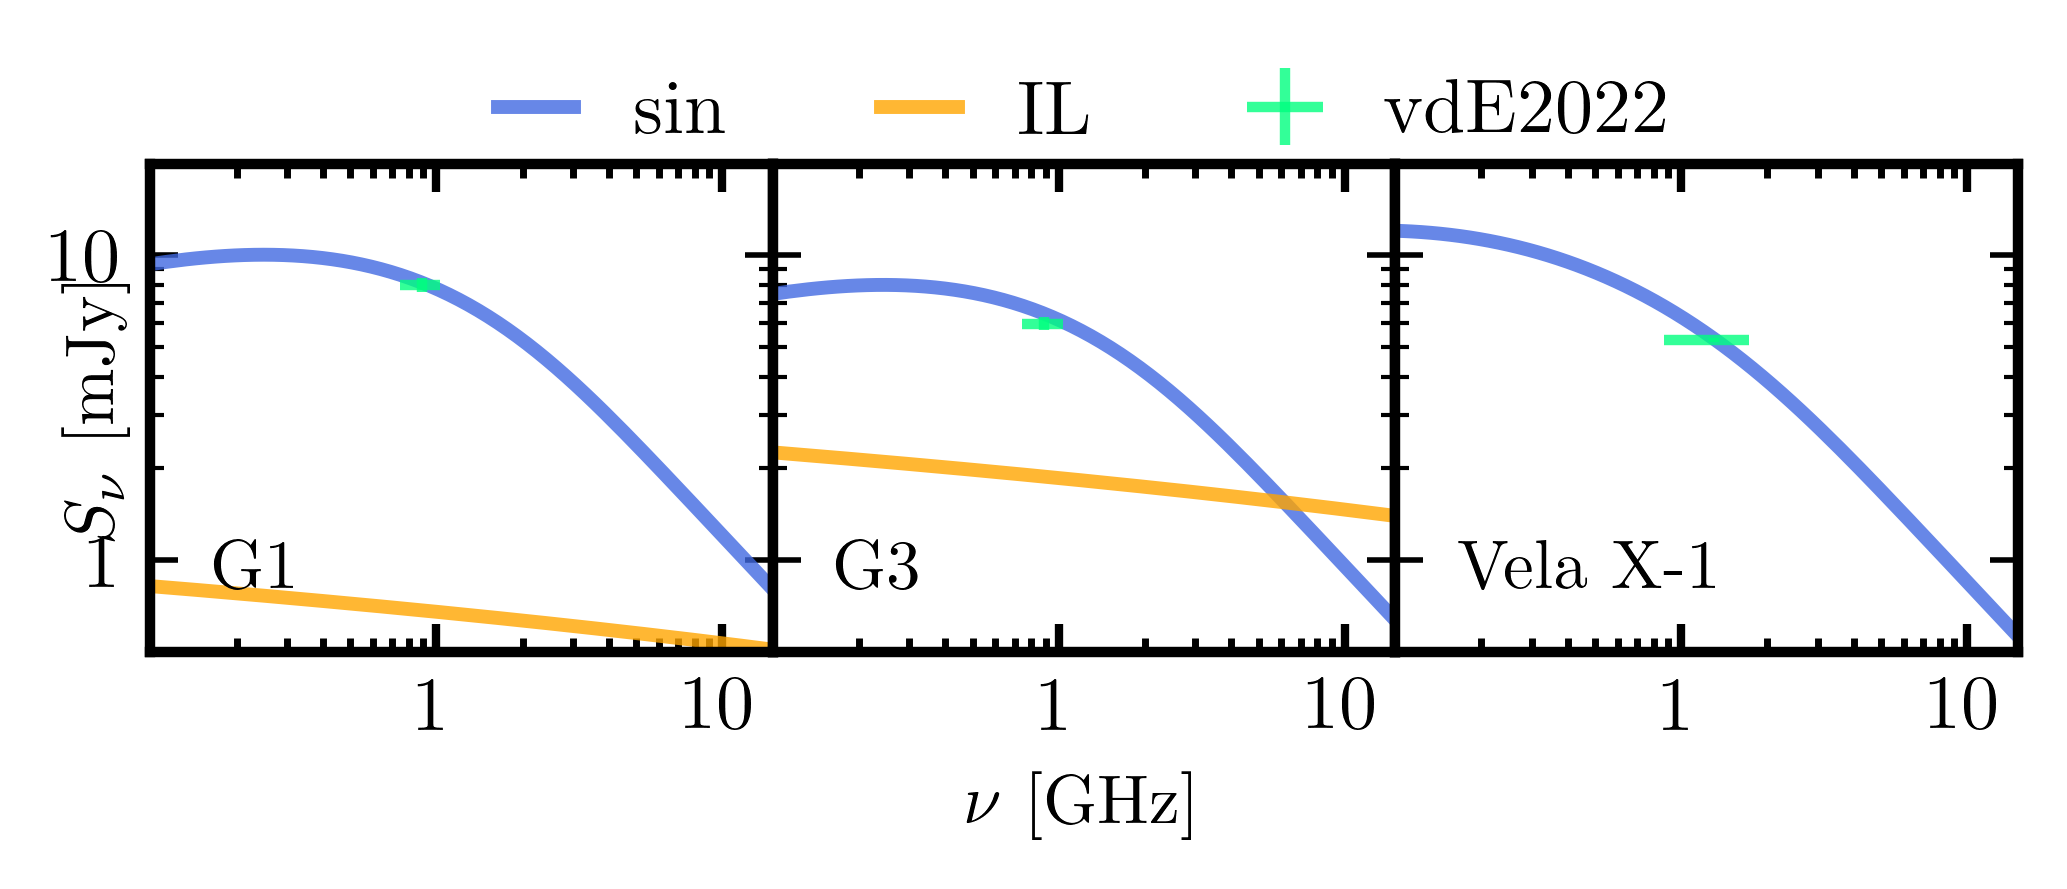

In [29]:
systems_B = ['G1', 'G3', 'Vela_X-1']

fig, ax = plt.subplots(
    1, 3,
    figsize=(0.9*text_width, 0.6*text_width/3),
    sharex=True,
    sharey=True
)

for i, sys in enumerate(systems_B):

    axi = ax[i]

    axi.set_xscale('log')
    axi.set_yscale('log')

    axi.plot(
        data[sys]["nu_syn"],
        data[sys]["syn"],
        color="royalblue", lw=2, alpha=0.8,
        label=r"sin"
    )
    
    axi.plot(
        data[sys]["nu_ff_IL"],
        data[sys]["ff_IL"],
        color="orange", lw=2, alpha=0.8,
        label=r"IL"
    )
    
    #axi.plot(
    #    total[sys]["nu_tot"],
    #    total[sys]["S_tot"],
    #    color="darkred", lw=3, alpha=0.8,
    #    label='total'
    #)
    
    if i==0:
        # G1
        axi.errorbar(nu_VdE, G1, yerr=G1_err, xerr=nu_VdE_err, ecolor='springgreen', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)
        axi.annotate(f"{sys}",
                xy=(0.1,0.1),
                xycoords="axes fraction",
                ha="left",
                va="bottom"
                )
    elif i==1:
        # HD 319881 -- G3
        axi.errorbar(nu_VdE, HD_319881, yerr=HD_319881_err, xerr=nu_VdE_err, ecolor='springgreen', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)
        axi.annotate(f"{sys}",
                xy=(0.1,0.1),
                xycoords="axes fraction",
                ha="left",
                va="bottom"
                )
    elif i==2:
        # Vela X-1
        axi.errorbar(nu_VX1, V_X1, yerr=V_X1_err, xerr=nu_VX1_err, ecolor='springgreen', alpha=0.8, fmt='none', label = 'vdE2022',zorder=2)
        axi.annotate("Vela X-1",
                xy=(0.1,0.1),
                xycoords="axes fraction",
                ha="left",
                va="bottom"
                )
    
    axi.set_xlim(0.1, 15)
    ticks_x = [1, 10]
    axi.set_xticks(ticks_x)
    axi.set_xticklabels([f"{t:g}" for t in ticks_x])

    axi.set_ylim(0.5, 20)
    ticks_y = [1, 10]
    axi.set_yticks(ticks_y)
    axi.set_yticklabels([f"{int(t)}" for t in ticks_y])
    ticks_y_minor = [1,2,3,4,5,6,7,8,9]
    axi.set_yticks(ticks_y_minor, minor=True)

    axi.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

    axi.xaxis.set_minor_formatter(NullFormatter())
    axi.yaxis.set_minor_formatter(NullFormatter())

# ===== Global labels =====
fig.subplots_adjust(
    left=0.16,
    right=0.84,
    bottom=0.10,
    top=0.90,
    wspace=0.
)

sp = fig.subplotpars
xmid = (sp.left + sp.right) / 2
ymid = (sp.bottom + sp.top) / 2

fig.text(
    sp.left - 0.02, ymid,
    r"$S_\nu$ [mJy]",
    rotation="vertical",
    ha="center",
    va="center"
)

fig.text(
    xmid, sp.bottom - 0.25,
    r"$\nu$ [GHz]",
    ha="center",
    va="center"
)

handles_all = []
labels_all = []

for axi in ax:
    h, l = axi.get_legend_handles_labels()
    for hi, li in zip(h, l):
        if li and li not in labels_all:
            handles_all.append(hi)
            labels_all.append(li)

fig.legend(
    handles_all,
    labels_all,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=4,
    frameon=False,
    handlelength=1.
)

plt.show()

In [30]:
#fig.savefig('SED_G1_G3_Vela.pdf', bbox_inches='tight', pad_inches = 0.01)